In [4]:
import os
import argparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import pandas as pd
from Bio import SeqIO

In [2]:
def get_mean_off_diagonal(csv_path):
    """Reads a distance/divergence matrix and returns the mean of off-diagonal elements."""
    try:
        df = pd.read_csv(csv_path, index_col=0)
        vals = df.values
        np.fill_diagonal(vals, np.nan)
        return np.nanmean(vals)
    except Exception as e:
        print(f"Error reading {csv_path}: {e}")
        return np.nan

def load_collective_data(base_dir):
    """Scans the results directory and aggregates data across all seasons."""
    print(f"Scanning {base_dir} for season and model variant data...")
    
    pos_data, zone_att_data, clade_att_data = [], [], []
    zone_div_data, clade_div_data, epistasis_data = [], [], []

    base_path = Path(base_dir)
    if not base_path.exists():
        print(f"Directory {base_dir} does not exist.")
        return [pd.DataFrame()] * 6

    season_dirs = sorted([d for d in base_path.iterdir() if d.is_dir() and d.name.isdigit()])

    for season_dir in season_dirs:
        season = int(season_dir.name)
        for variant_dir in [d for d in season_dir.iterdir() if d.is_dir()]:
            variant_name = variant_dir.name
            
            # 1. Position Attention
            pos_file = variant_dir / "d1_position_attention.csv"
            if pos_file.exists():
                df = pd.read_csv(pos_file)
                df['Season'], df['Model'] = season, variant_name
                pos_data.append(df)
            
            # 2. Zone & Clade Attention
            for att_file, data_list in zip(["d1_zone_attention.csv", "d1_clade_attention.csv"], 
                                           [zone_att_data, clade_att_data]):
                fpath = variant_dir / att_file
                if fpath.exists():
                    df = pd.read_csv(fpath)
                    df['Season'], df['Model'] = season, variant_name
                    data_list.append(df)
                
            # 3. Divergence
            for div_file, data_list, col_name in zip(["c1_zone_divergence.csv", "c2_clade_divergence.csv"], 
                                                     [zone_div_data, clade_div_data], 
                                                     ['Zone_Divergence', 'Clade_Divergence']):
                fpath = variant_dir / div_file
                if fpath.exists():
                    data_list.append({'Season': season, 'Model': variant_name, col_name: get_mean_off_diagonal(fpath)})
                
            # 4. Epistasis
            epi_file = variant_dir / "b1_epistasis_pairs.csv"
            if not epi_file.exists(): epi_file = variant_dir / "b1_epistasis_pairs_masked.csv"
            if epi_file.exists():
                df = pd.read_csv(epi_file)
                df['Season'], df['Model'] = season, variant_name
                epistasis_data.append(df)

    df_pos = pd.concat(pos_data, ignore_index=True) if pos_data else pd.DataFrame()
    df_zone_att = pd.concat(zone_att_data, ignore_index=True) if zone_att_data else pd.DataFrame()
    df_clade_att = pd.concat(clade_att_data, ignore_index=True) if clade_att_data else pd.DataFrame()
    df_zone_div = pd.DataFrame(zone_div_data) if zone_div_data else pd.DataFrame()
    df_clade_div = pd.DataFrame(clade_div_data) if clade_div_data else pd.DataFrame()
    df_epi = pd.concat(epistasis_data, ignore_index=True) if epistasis_data else pd.DataFrame()

    return df_pos, df_zone_att, df_clade_att, df_zone_div, df_clade_div, df_epi

In [3]:
# SET YOUR FOLDER PATH HERE
RESULTS_DIR = "/home/apone/fluml/inspection_results"

# Load the data into memory
df_pos, df_zone_att, df_clade_att, df_zone_div, df_clade_div, df_epi = load_collective_data(RESULTS_DIR)

# Get unique models
all_models = sorted(list(df_pos['Model'].unique()))
print(f"\nModels available to plot: {all_models}")

# Select ONE model to focus our custom graphing on
#TARGET_MODEL = all_models[0] if all_models else None
TARGET_MODEL = "Transformer_3L"
print(f"Targeting model for graphs: {TARGET_MODEL}")

# Slice the dataframes for just this model
m_pos = df_pos[df_pos['Model'] == TARGET_MODEL]
m_zone_att = df_zone_att[df_zone_att['Model'] == TARGET_MODEL]
m_clade_att = df_clade_att[df_clade_att['Model'] == TARGET_MODEL]
m_zone_div = df_zone_div[df_zone_div['Model'] == TARGET_MODEL]
m_clade_div = df_clade_div[df_clade_div['Model'] == TARGET_MODEL]
m_epi = df_epi[df_epi['Model'] == TARGET_MODEL]

Scanning /home/apone/fluml/inspection_results for season and model variant data...

Models available to plot: ['Lstm_baseline', 'Transformer_3L', 'Transformer_4L', 'Transformer_5L']
Targeting model for graphs: Transformer_3L


Generating Master Zone Divergence Dendrogram...


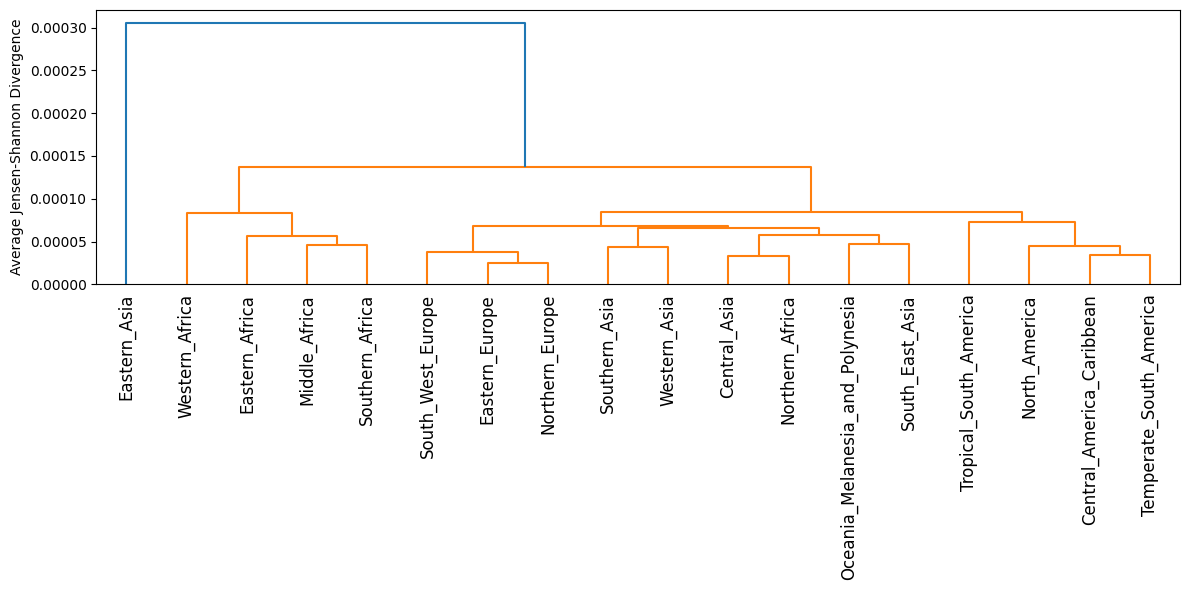


Generating Master Clade Divergence Dendrogram...


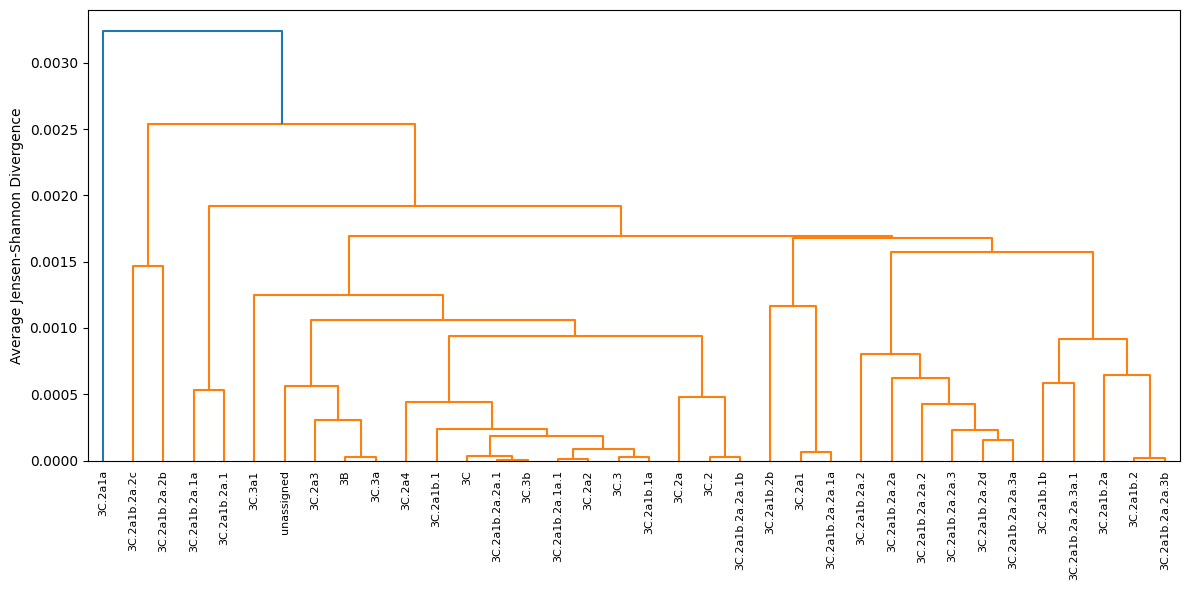

In [5]:
import glob
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, dendrogram

def plot_master_dendrogram(base_dir, model_name, target_file, title):
    # Find all target files (e.g., c1_zone_divergence.csv) for this specific model across ALL seasons
    search_pattern = os.path.join(base_dir, "*", model_name, target_file)
    files = glob.glob(search_pattern)
    
    if not files:
        print(f"No files found for {target_file} under {model_name}")
        return
        
    # Read and accumulate all matrices
    all_dfs = []
    for f in files:
        df = pd.read_csv(f, index_col=0)
        all_dfs.append(df)
        
    # Safely average them together. 
    # pd.concat handles aligning different clades that only existed in certain years.
    master_df = pd.concat(all_dfs).groupby(level=0).mean()
    
    # Ensure columns and indices match perfectly
    master_df = master_df.reindex(index=master_df.columns)
    
    # Drop items that are entirely NaN
    master_df = master_df.dropna(axis=0, how='all').dropna(axis=1, how='all')
    
    # Fill remaining NaNs (clades that never co-existed) with the maximum divergence penalty
    max_div = master_df.max().max()
    master_df = master_df.fillna(max_div)
    
    # Force perfect symmetry (corrects tiny floating point math errors from averaging)
    vals = master_df.values
    vals = (vals + vals.T) / 2.0
    np.fill_diagonal(vals, 0.0)
    
    # Convert to condensed distance matrix for SciPy
    condensed_dist = squareform(vals)
    
    # Calculate hierarchical clustering
    Z = linkage(condensed_dist, method='average')
    
    # Plotting
    plt.figure(figsize=(12, 6))
    dendrogram(Z, labels=master_df.columns, leaf_rotation=90, color_threshold=max_div*0.7)
    plt.title(title)
    plt.ylabel("Average Jensen-Shannon Divergence")
    plt.grid(False)
    plt.tight_layout()
    output_filename = target_file.replace('.csv', '.png')
    plt.savefig(f"{model_name}_{output_filename}", dpi=300, bbox_inches='tight')
    plt.show()

# --- EXECUTE THE PLOTS ---

print("Generating Master Zone Divergence Dendrogram...")
plot_master_dendrogram(
    base_dir=RESULTS_DIR, 
    model_name=TARGET_MODEL, 
    target_file="c1_zone_divergence.csv", 
    title = ""
    #title=f"Geographic Clustering (10-Year Average) [{TARGET_MODEL}]"
)

print("\nGenerating Master Clade Divergence Dendrogram...")
plot_master_dendrogram(
    base_dir=RESULTS_DIR, 
    model_name=TARGET_MODEL, 
    target_file="c2_clade_divergence.csv", 
    title = ""
    #title=f"Master Lineage Behavioral Clustering (10-Year Average) [{TARGET_MODEL}]"
)

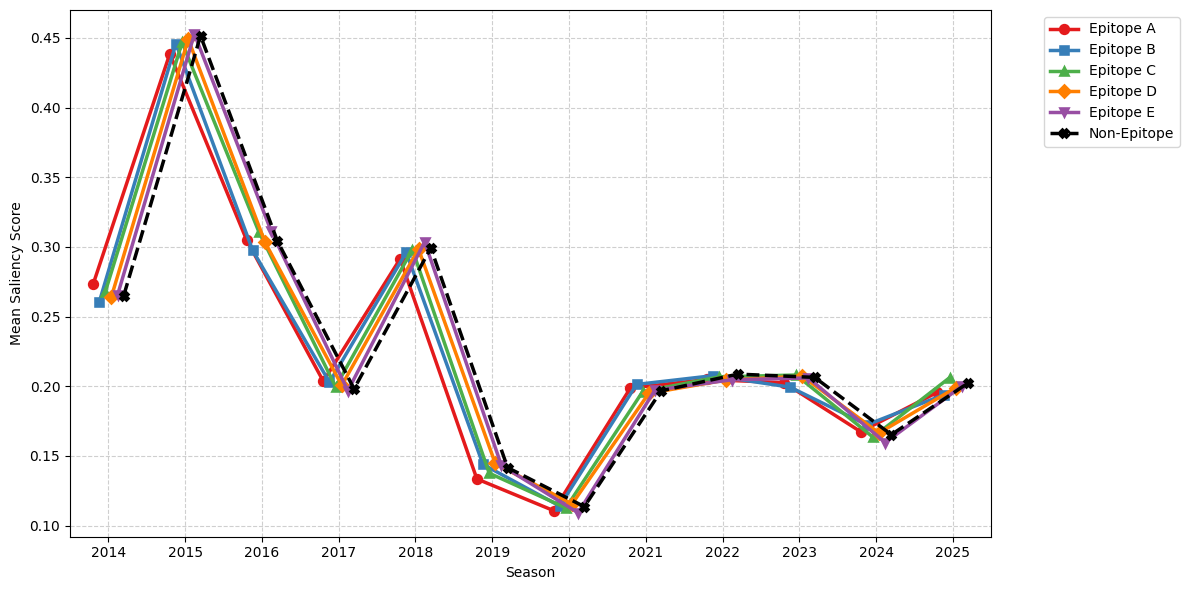

In [6]:
# Define the known epitopes from your model script
epitope_sites = {
    'A': [122, 124, 126, 130, 131, 132, 133, 135, 137, 138, 140, 142, 143, 144, 145, 146, 150, 152, 168],
    'B': [128, 129, 155, 156, 157, 158, 159, 160, 163, 164, 165, 186, 187, 188, 189, 190, 192, 193, 194, 196, 197, 198],
    'C': [44, 45, 46, 47, 48, 50, 51, 53, 54, 273, 275, 276, 278, 279, 280, 294, 297, 299, 300, 304, 305, 307, 308, 309, 310, 311, 312],
    'D': [96, 102, 103, 117, 121, 167, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 201, 203, 207, 208, 209, 212, 213, 214, 215, 216, 217, 218, 219, 226, 227, 228, 229, 230, 238, 240, 242, 244, 246, 247, 248],
    'E': [57, 59, 62, 63, 67, 75, 78, 80, 81, 82, 83, 86, 87, 88, 91, 92, 94, 109, 260, 261, 262, 265]
}

# Map each position to its epitope (or 'Non-Epitope')
def get_epitope(pos):
    for ep, sites in epitope_sites.items():
        if pos in sites: return f"Epitope {ep}"
    return "Non-Epitope"

m_pos_epi = m_pos.copy()
m_pos_epi['Region'] = m_pos_epi['Position'].apply(get_epitope)

# Calculate mean attention per region per season
region_attention = m_pos_epi.groupby(['Season', 'Region'])['Attention_Score'].mean().reset_index()

# Define explicit colors: bright colors for epitopes, black for the baseline
custom_palette = {
    'Epitope A': '#e41a1c', # Red
    'Epitope B': '#377eb8', # Blue
    'Epitope C': '#4daf4a', # Green
    'Epitope D': '#ff7f00', # Orange
    'Epitope E': '#984ea3', # Purple
    'Non-Epitope': '#000000' # Black baseline
}

# Define explicit line styles: solid for epitopes, dashed for the baseline
custom_dashes = {
    'Epitope A': '', 
    'Epitope B': '', 
    'Epitope C': '', 
    'Epitope D': '', 
    'Epitope E': '', 
    'Non-Epitope': (4, 4) # Dashed line
}

plt.figure(figsize=(12, 6))
sns.pointplot(
    data=region_attention, 
    x='Season', 
    y='Attention_Score', 
    hue='Region', 
    palette=custom_palette, 
    dodge=0.4,             # Shifts overlapping points side-by-side
    markers=['o', 's', '^', 'D', 'v', 'X'], 
    linestyles=['-', '-', '-', '-', '-', '--'],
    linewidth=2.5
)

#plt.title(f"Model Attention by HA Antigenic Region [{TARGET_MODEL}]")
plt.ylabel("Mean Saliency Score")
plt.xlabel("Season")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('position_attention.png', dpi=300, bbox_inches='tight')
plt.show()

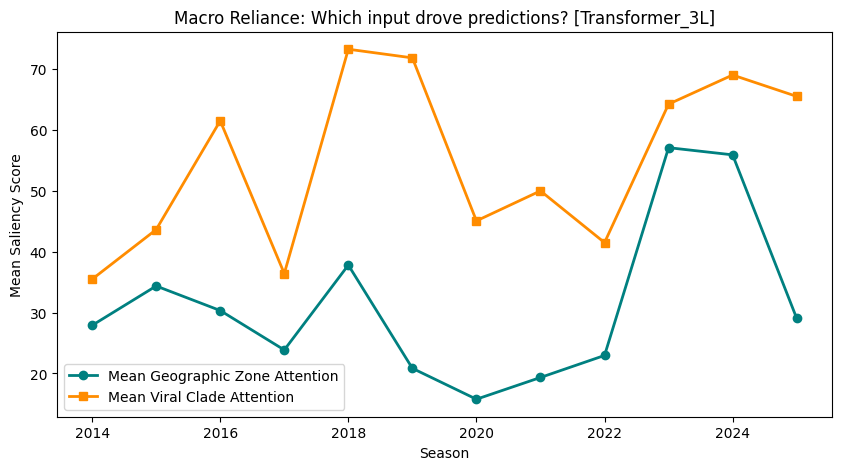

In [7]:
# Calculate the mean attention score for Zones and Clades per season
avg_zone = m_zone_att.groupby('Season')['Attention_Score'].mean().reset_index()
avg_clade = m_clade_att.groupby('Season')['Attention_Score'].mean().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(avg_zone['Season'], avg_zone['Attention_Score'], label='Mean Geographic Zone Attention', marker='o', color='teal', linewidth=2)
plt.plot(avg_clade['Season'], avg_clade['Attention_Score'], label='Mean Viral Clade Attention', marker='s', color='darkorange', linewidth=2)

plt.title(f"Macro Reliance: Which input drove predictions? [{TARGET_MODEL}]")
plt.ylabel("Mean Saliency Score")
plt.xlabel("Season")
plt.legend()
plt.savefig('zone_clade_attention.png', dpi=300, bbox_inches='tight')
plt.show()

In [9]:

# ==========================================
# 1. Re-build Historical Dictionary from FASTA
# ==========================================
print("Parsing FASTA to build historical AA dictionary...")
historical_aas = {}
# Replace with your actual fasta path if needed
for record in SeqIO.parse("/home/apone/fluml/h3n2_clean.fasta", "fasta"):
    for pos, aa in enumerate(str(record.seq)):
        aa_upper = aa.upper()
        if aa_upper not in ['-', 'X']:
            if pos not in historical_aas:
                historical_aas[pos] = set()
            historical_aas[pos].add(aa_upper)

# Re-evaluate the 'Historically_Observed' column in your DataFrame
# Assuming Mutated_Pos is 1-indexed in the DF, we subtract 1 for the 0-indexed dict
def check_historical(row):
    pos = int(row['Mutated_Pos']) - 1 
    mut_aa = row['Mutation'].upper()
    return "Yes" if mut_aa in historical_aas.get(pos, set()) else "No"

m_epi['Historically_Observed'] = m_epi.apply(check_historical, axis=1)

# ==========================================
# 2. Define Amino Acid Property Groups
# ==========================================
# Grouping AAs by their biochemical properties
aa_properties = {
    'Hydrophobic': {'A', 'V', 'I', 'L', 'M', 'F', 'Y', 'W'},
    'Polar_Uncharged': {'S', 'T', 'N', 'Q'},
    'Positively_Charged': {'R', 'H', 'K'},
    'Negatively_Charged': {'D', 'E'},
    'Special': {'C', 'G', 'P'} # Often disrupt structure, usually only swap with themselves
}

# Reverse mapping: AA -> Property Group
aa_to_group = {}
for group, aas in aa_properties.items():
    for aa in aas:
        aa_to_group[aa] = group

def is_conservative(orig_aa, mut_aa):
    """Check if the mutation stays within the same biochemical group"""
    orig_group = aa_to_group.get(orig_aa.upper())
    mut_group = aa_to_group.get(mut_aa.upper())
    
    # If either AA is unrecognized, default to False
    if not orig_group or not mut_group:
        return False
        
    return orig_group == mut_group



Parsing FASTA to build historical AA dictionary...


/tmp/ipykernel_145816/3783643270.py:22: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  m_epi['Historically_Observed'] = m_epi.apply(check_historical, axis=1)


In [11]:
top_network_pairs = m_epi[(m_epi["Distance_1D"] > 5)].copy()

# Split the data
historical_df = top_network_pairs[top_network_pairs['Historically_Observed'] == 'Yes']
non_historical_df = top_network_pairs[top_network_pairs['Historically_Observed'] == 'No']

filtered_network_pairs = top_network_pairs[
    (top_network_pairs['Historically_Observed'] == 'Yes') & 
    (top_network_pairs['Impact_Score'] >= 0.5) 
]
#filtered_network_pairs = filtered_network_pairs.sort_values('Impact_Score', ascending=False) \
 #                                  .groupby('Mutated_Pos').head(1)
len(filtered_network_pairs)

649

In [12]:
import numpy as np
import pandas as pd
from datetime import datetime
from Bio import SeqIO
from scipy.stats import chi2_contingency

# ==========================================
# 1. FASTA Parser (Your provided function)
# ==========================================
def load_fasta(fasta_path):
    print(f"Loading FASTA: {fasta_path}...")
    all_parsed_data = []
    for record in SeqIO.parse(fasta_path, "fasta"):
        fields = record.id.split('|')
        if len(fields) < 6:
            continue
            
        unique_id = fields[0].strip()
        subtype   = fields[1].strip()
        clade     = fields[2].strip()
        date_str  = fields[3].strip()
        country   = fields[4].strip()
        zone      = fields[5].strip()
        
        try:
            date = datetime.strptime(date_str, '%Y-%m-%d')
            # Keep gaps (-), only remove stop codons (*)
            raw_seq = str(record.seq).replace('*', '')
            
            # Check length and cut conditionally
            if len(raw_seq) >= 553:
                sequence = raw_seq[16:]
            else:
                sequence = raw_seq
                
            all_parsed_data.append(dict(
                date=date, sequence=sequence,
                id_full_header=record.id, unique_id=unique_id,
                clade=clade, subtype=subtype, country=country, zone=zone
            ))
        except ValueError:
            continue
            
    df = pd.DataFrame(all_parsed_data)
    print(f"Total records parsed: {len(df)}")
    return df

# ==========================================
# 2. Seasonal Logic
# ==========================================
def assign_custom_season(date, target_year):
    """
    Tags a sequence as either 'Training' or 'Target' for a specific model year.
    Returns None if the sequence falls outside both windows.
    """
    # Training Window: Jul Y-3 to Jan Y
    train_start = datetime(target_year - 3, 7, 1)
    train_end = datetime(target_year, 1, 31)
    
    # Target Window: Jul Y to Jan Y+1
    target_start = datetime(target_year, 7, 1)
    target_end = datetime(target_year + 1, 1, 31)
    
    if train_start <= date <= train_end:
        return "Training"
    elif target_start <= date <= target_end:
        return "Target"
    else:
        return None

# ==========================================
# 3. Build Seasonal Alignment Matrices
# ==========================================
# Load the dataset
fasta_df = load_fasta("/home/apone/fluml/h3n2_clean.fasta")

print("\n-> Building seasonal training matrices...")
unique_seasons = filtered_network_pairs['Season'].unique()
seasonal_matrices = {}

for target_year in unique_seasons:
    # Filter sequences that fall into this year's Training window
    mask = fasta_df['date'].apply(lambda d: assign_custom_season(d, target_year) == "Training")
    subset_df = fasta_df[mask]
    
    if subset_df.empty:
        seasonal_matrices[target_year] = None
        print(f"Season {target_year} Training Sequences: 0")
        continue
        
    # Convert sequences into a 2D numpy character array for fast column slicing
    seq_list = subset_df['sequence'].tolist()
    
    # Ensure all sequences are the same length (Standardizing alignment)
    mode_len = max(set([len(s) for s in seq_list]), key=[len(s) for s in seq_list].count)
    valid_seqs = [list(s) for s in seq_list if len(s) == mode_len]
    
    seasonal_matrices[target_year] = np.array(valid_seqs)
    print(f"Season {target_year} Training Sequences: {len(valid_seqs)} (Alignment Length: {mode_len})")

# ==========================================
# 4. The Dynamic Training Validation
# ==========================================
def seasonal_consensus_check(row):
    target_year = row['Season']
    
    # Check if we have data for this season
    if target_year not in seasonal_matrices or seasonal_matrices[target_year] is None:
        return None
        
    matrix = seasonal_matrices[target_year] 
    seq_len = matrix.shape[1]
    
    p_i = int(row['Mutated_Pos']) - 1
    p_j = int(row['Affected_Pos']) - 1
    model_aa = row['Mutation'] 
    
    if not (0 <= p_i < seq_len and 0 <= p_j < seq_len):
        return None

    # Extract target columns
    col_i = matrix[:, p_i]
    col_j = matrix[:, p_j]
    
    # Remove gaps/missing data
    valid = (col_i != '-') & (col_i != 'X') & (col_j != '-') & (col_j != 'X')
    if valid.sum() < 5:  
        return None
        
    col_i_valid = col_i[valid]
    col_j_valid = col_j[valid]
    
    # --- Dynamic Baseline Identification ---
    unique_mut, counts_mut = np.unique(col_i_valid, return_counts=True)
    sorted_indices = np.argsort(-counts_mut)
    rank1_aa = unique_mut[sorted_indices[0]]
    rank2_aa = unique_mut[sorted_indices[1]] if len(sorted_indices) > 1 else None

    if model_aa == rank1_aa:
        baseline_aa = rank2_aa 
        model_is_consensus = True
    else:
        baseline_aa = rank1_aa 
        model_is_consensus = False
        
    if baseline_aa is None:
        return None # 100% conserved in training data, cannot compute shift
        
    # --- Measure Frequencies ---
    state_a_mask = (col_i_valid == model_aa)
    state_b_mask = (col_i_valid == baseline_aa)
    
    total_a = state_a_mask.sum()
    total_b = state_b_mask.sum()
    
    if total_a == 0 or total_b == 0:
        return None

    # Target AA in Mutant Universe (State A)
    target_aas_a = col_j_valid[state_a_mask]
    u_tgt, c_tgt = np.unique(target_aas_a, return_counts=True)
    dom_target_aa = u_tgt[np.argmax(c_tgt)]
    freq_a = c_tgt.max() / total_a
    count_a_has_target = c_tgt.max()
    
    # Same Target AA in Baseline Universe (State B)
    target_aas_b = col_j_valid[state_b_mask]
    count_b_has_target = (target_aas_b == dom_target_aa).sum()
    freq_b = count_b_has_target / total_b
    
    # --- Statistical Testing ---
    table = [
        [count_a_has_target, total_a - count_a_has_target],
        [count_b_has_target, total_b - count_b_has_target]
    ]
    
    try:
        chi2, p_val, _, _ = chi2_contingency(table)
    except ValueError:
        p_val = 1.0

    return {
        'Train_Model_is_Consensus': model_is_consensus,
        'Train_MSA_Mutant_Count': total_a,
        'Train_Baseline_AA_Used': baseline_aa,
        'Train_Target_AA': dom_target_aa,
        'Train_Freq_Baseline': freq_b,
        'Train_Freq_Model_State': freq_a,
        'Train_Shift': freq_a - freq_b,
        'Train_P_Value': p_val
    }

# ==========================================
# 5. Apply and Merge Results
# ==========================================
print("\n-> Running seasonal validation check on predicted pairs...")
results_seasonal = filtered_network_pairs.apply(seasonal_consensus_check, axis=1)

# Drop pairs that lacked sufficient sequence data in their specific training window
valid_results_seasonal = results_seasonal.dropna()
res_seasonal_df = pd.DataFrame(valid_results_seasonal.tolist(), index=valid_results_seasonal.index)

# Merge back into the original dataframe
final_training_validated_df = filtered_network_pairs.loc[valid_results_seasonal.index].join(res_seasonal_df)

# Output Summary
total_tested = len(final_training_validated_df)
significant_shifts = (final_training_validated_df['Train_P_Value'] < 0.05).sum()
pct_significant = (significant_shifts / total_tested) * 100 if total_tested > 0 else 0

print(f"\n--- SEASONAL TRAINING DATA VALIDATION RESULTS ---")
print(f"Total pairs testable within their specific training window: {total_tested}")
print(f"Pairs showing statistically significant epistatic shift (p < 0.05): {significant_shifts}")
print(f"Percentage of validated structural shifts from training context: {pct_significant:.1f}%")

Loading FASTA: /home/apone/fluml/h3n2_clean.fasta...
Total records parsed: 193102

-> Building seasonal training matrices...
Season 2016 Training Sequences: 13555 (Alignment Length: 550)
Season 2018 Training Sequences: 27587 (Alignment Length: 550)
Season 2019 Training Sequences: 32298 (Alignment Length: 550)
Season 2020 Training Sequences: 32940 (Alignment Length: 550)
Season 2021 Training Sequences: 22370 (Alignment Length: 550)
Season 2022 Training Sequences: 17887 (Alignment Length: 550)
Season 2023 Training Sequences: 48846 (Alignment Length: 550)
Season 2024 Training Sequences: 65387 (Alignment Length: 550)

-> Running seasonal validation check on predicted pairs...

--- SEASONAL TRAINING DATA VALIDATION RESULTS ---
Total pairs testable within their specific training window: 242
Pairs showing statistically significant epistatic shift (p < 0.05): 7
Percentage of validated structural shifts from training context: 2.9%


In [13]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from Bio import AlignIO
from sklearn.metrics import mutual_info_score
from scipy.stats import spearmanr
from scipy.stats import chi2_contingency

# 1. Read alignment from h3n2.fasta
alignment = AlignIO.read("/home/apone/fluml/h3n2_clean.fasta", "fasta")
seqs = [list(str(record.seq).upper()) for record in alignment]
alignment_matrix = np.array(seqs)
num_seqs, seq_len = alignment_matrix.shape

def dynamic_consensus_check(row):
    p_i = int(row['Mutated_Pos']) - 1
    p_j = int(row['Affected_Pos']) - 1
    model_aa = row['Mutation'] 
    
    if not (0 <= p_i < seq_len and 0 <= p_j < seq_len):
        return None

    col_i = alignment_matrix[:, p_i]
    col_j = alignment_matrix[:, p_j]
    
    # Filter valid sequences
    valid = (col_i != '-') & (col_i != 'X') & (col_j != '-') & (col_j != 'X')
    if valid.sum() < 10:
        return None
        
    col_i_valid = col_i[valid]
    col_j_valid = col_j[valid]
    
    # --- YOUR DYNAMIC LOGIC ---
    # 1. Find rank 1 and rank 2 AAs at the mutated position
    unique_mut, counts_mut = np.unique(col_i_valid, return_counts=True)
    sorted_indices = np.argsort(-counts_mut)
    rank1_aa = unique_mut[sorted_indices[0]]
    
    # Handle highly conserved sites (only 1 AA exists)
    if len(sorted_indices) > 1:
        rank2_aa = unique_mut[sorted_indices[1]]
    else:
        rank2_aa = None

    # 2. Assign State B (The Comparison Baseline)
    if model_aa == rank1_aa:
        baseline_aa = rank2_aa  # Model picked the consensus, compare to the next best
        model_is_consensus = True
    else:
        baseline_aa = rank1_aa  # Model picked a variant, compare to consensus
        model_is_consensus = False
        
    if baseline_aa is None:
        return None # Cannot compare if there is 100% conservation and no second AA
        
    # 3. Build Universes
    state_a_mask = (col_i_valid == model_aa)
    state_b_mask = (col_i_valid == baseline_aa)
    
    total_a = state_a_mask.sum()
    total_b = state_b_mask.sum()
    
    if total_a == 0 or total_b == 0:
        return None

    # 4. Target AA in State A
    target_aas_a = col_j_valid[state_a_mask]
    u_tgt, c_tgt = np.unique(target_aas_a, return_counts=True)
    dom_target_aa = u_tgt[np.argmax(c_tgt)]
    freq_a = c_tgt.max() / total_a
    count_a_has_target = c_tgt.max()
    
    # 5. Same Target AA in State B
    target_aas_b = col_j_valid[state_b_mask]
    count_b_has_target = (target_aas_b == dom_target_aa).sum()
    freq_b = count_b_has_target / total_b
    
    # --- STATISTICAL TESTING ---
    # Contingency Table: [ [A_has_target, A_doesnt], [B_has_target, B_doesnt] ]
    table = [
        [count_a_has_target, total_a - count_a_has_target],
        [count_b_has_target, total_b - count_b_has_target]
    ]
    # Calculate p-value. Use Chi-square (with Yates correction) for large numbers
    try:
        chi2, p_val, _, _ = chi2_contingency(table)
    except ValueError:
        p_val = 1.0

    shift = freq_a - freq_b
    
    return {
        'Model_is_Consensus': model_is_consensus,
        'Baseline_AA_Used': baseline_aa,
        'Target_AA': dom_target_aa,
        'MSA_Mutant_Count': total_a,
        'Freq_in_Baseline': freq_b,
        'Freq_in_Model_State': freq_a,
        'Shift': shift,
        'P_Value': p_val
    }

# Apply logic and extract results
results = filtered_network_pairs.apply(dynamic_consensus_check, axis=1)

In [24]:
import pandas as pd
from statsmodels.stats.multitest import multipletests

# ==========================================
# 1. Process Global Data & Apply Correction
# ==========================================
# Extract valid global results (ignoring Nones)
valid_global = results.dropna()
global_df = pd.DataFrame(valid_global.tolist(), index=valid_global.index)

# Apply Bonferroni correction to Global P-Values
_, pvals_adj_global, _, _ = multipletests(global_df['P_Value'], alpha=0.05, method='bonferroni')
global_df['P_Value_Adj'] = pvals_adj_global

# Combine back with the original pair info
final_global_df = filtered_network_pairs.loc[valid_global.index].join(global_df)

# ==========================================
# 2. Process Seasonal Data & Apply Correction
# ==========================================
# Extract valid seasonal results
valid_seasonal = results_seasonal.dropna()
seasonal_df = pd.DataFrame(valid_seasonal.tolist(), index=valid_seasonal.index)

# Apply Bonferroni correction to Seasonal P-Values
_, pvals_adj_seasonal, _, _ = multipletests(seasonal_df['Train_P_Value'], alpha=0.05, method='bonferroni')
seasonal_df['Train_P_Value_Adj'] = pvals_adj_seasonal

# Combine back with the original pair info
final_training_validated_df = filtered_network_pairs.loc[valid_seasonal.index].join(seasonal_df)


# ==========================================
# 3. Compare Raw vs. Adjusted Counts
# ==========================================
# Global counts
global_raw_sig = (global_df['P_Value'] < 0.05).sum()
global_adj_sig = (global_df['P_Value_Adj'] < 0.05).sum()

# Seasonal counts
seasonal_raw_sig = (seasonal_df['Train_P_Value'] < 0.05).sum()
seasonal_adj_sig = (seasonal_df['Train_P_Value_Adj'] < 0.05).sum()

print("\n=== MULTIPLE TESTING CORRECTION SUMMARY ===")
print(f"Total candidate pairs evaluated: {len(filtered_network_pairs)}")
print("-" * 50)
print("GLOBAL POOL (Complete Dataset):")
print(f"  Significant pairs (Raw p < 0.05):      {global_raw_sig}")
print(f"  Significant pairs (Adjusted p < 0.05): {global_adj_sig}")
print(f"  False positives filtered out:          {global_raw_sig - global_adj_sig}")
print("-" * 50)
print("SEASONAL POOL (Training Windows Only):")
print(f"  Significant pairs (Raw p < 0.05):      {seasonal_raw_sig}")
print(f"  Significant pairs (Adjusted p < 0.05): {seasonal_adj_sig}")
print(f"  False positives filtered out:          {seasonal_raw_sig - seasonal_adj_sig}")
print("===========================================\n")


=== MULTIPLE TESTING CORRECTION SUMMARY ===
Total candidate pairs evaluated: 649
--------------------------------------------------
GLOBAL POOL (Complete Dataset):
  Significant pairs (Raw p < 0.05):      123
  Significant pairs (Adjusted p < 0.05): 110
  False positives filtered out:          13
--------------------------------------------------
SEASONAL POOL (Training Windows Only):
  Significant pairs (Raw p < 0.05):      7
  Significant pairs (Adjusted p < 0.05): 7
  False positives filtered out:          0



In [25]:
import pandas as pd

# ==========================================
# 1. CREATE AND MERGE comparison_df
# ==========================================
# Start with your global dataframe which now has P_Value_Adj
comparison_df = final_global_df.copy()

# Merge in the seasonal adjusted p-values and counts
comparison_df = pd.merge(
    comparison_df,
    final_training_validated_df[['Mutated_Pos', 'Affected_Pos', 'Train_P_Value_Adj', 'Train_MSA_Mutant_Count']],
    on=['Mutated_Pos', 'Affected_Pos'],
    how='left'
)

# Fill missing seasonal data with defaults (if a pair wasn't found in the training window)
comparison_df['Train_P_Value_Adj'] = comparison_df['Train_P_Value_Adj'].fillna(1.0)
comparison_df['Train_MSA_Mutant_Count'] = comparison_df['Train_MSA_Mutant_Count'].fillna(0)

# Sort and deduplicate to get unique positional linkages
comparison_df = comparison_df.sort_values(
    by=['P_Value_Adj', 'MSA_Mutant_Count', 'Impact_Score'], 
    ascending=[True, False, False]
)
comparison_df = comparison_df.drop_duplicates(subset=['Mutated_Pos', 'Affected_Pos'])

# ==========================================
# 2. APPLY CATEGORIZATION LOGIC
# ==========================================
def categorize_stacked_data(row):
    # Check significance using the ADJUSTED p-values
    global_sig = row['P_Value_Adj'] < 0.05 
    train_sig = row['Train_P_Value_Adj'] < 0.05
    global_count = row.get('MSA_Mutant_Count', 0)
    train_count = row.get('Train_MSA_Mutant_Count', 0)
    
    # Define X-Axis Tier (matching your graph's specific text)
    if global_sig:
        if global_count >= 5:
            x_tier = "Validated\n(Sufficient: >=5 seqs)"
        else:
            x_tier = "Validated\n(Rare: <5 seqs)"
    elif global_count >= 5:
        x_tier = "Observed\n(Non-Significant)"
    else:
        x_tier = "Empirically\nUnobserved"
        
    # Define Stack Group (Foresight vs Established)
    if train_sig or (train_count >= 5 and not global_sig):
        if global_sig:
            stack_group = "In Both (Global & Seasonal)"
        else:
            stack_group = "Seasonal Only"
    else:
        stack_group = "Total (Global) Pool Only"
        
    return pd.Series({'X_Tier': x_tier, 'Stack_Group': stack_group})

# Apply the logic
cat_results = comparison_df.apply(categorize_stacked_data, axis=1)
comparison_df['X_Tier'] = cat_results['X_Tier']
comparison_df['Stack_Group'] = cat_results['Stack_Group']

print(f"comparison_df created successfully with {len(comparison_df)} unique pairs.")

comparison_df created successfully with 473 unique pairs.


In [26]:
# ==========================================
print("\n=== FINAL COMPARISON DATAFRAME SUMMARY ===")
print(f"Total unique positional linkages: {len(comparison_df)}")
print("-" * 50)

print("BREAKDOWN BY SIGNIFICANCE (Adjusted P-Values):")
global_adj_sig = (comparison_df['P_Value_Adj'] < 0.05).sum()
seasonal_adj_sig = (comparison_df['Train_P_Value_Adj'] < 0.05).sum()
both_sig = ((comparison_df['P_Value_Adj'] < 0.05) & (comparison_df['Train_P_Value_Adj'] < 0.05)).sum()

print(f"  Significant in Global:   {global_adj_sig}")
print(f"  Significant in Seasonal: {seasonal_adj_sig}")
print(f"  Significant in BOTH:     {both_sig}")
print("-" * 50)

print("BREAKDOWN BY X-AXIS TIER:")
tier_counts = comparison_df['X_Tier'].value_counts()
for tier, count in tier_counts.items():
    # Replace newlines for cleaner console printing
    clean_tier = tier.replace('\n', ' ')
    print(f"  {clean_tier}: {count}")
print("-" * 50)

print("BREAKDOWN BY STACK GROUP:")
stack_counts = comparison_df['Stack_Group'].value_counts()
for group, count in stack_counts.items():
    print(f"  {group}: {count}")
print("==========================================\n")


=== FINAL COMPARISON DATAFRAME SUMMARY ===
Total unique positional linkages: 473
--------------------------------------------------
BREAKDOWN BY SIGNIFICANCE (Adjusted P-Values):
  Significant in Global:   105
  Significant in Seasonal: 6
  Significant in BOTH:     6
--------------------------------------------------
BREAKDOWN BY X-AXIS TIER:
  Empirically Unobserved: 305
  Validated (Rare: <5 seqs): 96
  Observed (Non-Significant): 63
  Validated (Sufficient: >=5 seqs): 9
--------------------------------------------------
BREAKDOWN BY STACK GROUP:
  Total (Global) Pool Only: 450
  Seasonal Only: 17
  In Both (Global & Seasonal): 6



In [18]:
all_epitope_positions = [pos for sites in epitope_sites.values() for pos in sites]
epitope_sites = {
    'A': [122, 124, 126, 130, 131, 132, 133, 135, 137, 138, 140, 142, 143, 144, 145, 146, 150, 152, 168],
    'B': [128, 129, 155, 156, 157, 158, 159, 160, 163, 164, 165, 186, 187, 188, 189, 190, 192, 193, 194, 196, 197, 198],
    'C': [44, 45, 46, 47, 48, 50, 51, 53, 54, 273, 275, 276, 278, 279, 280, 294, 297, 299, 300, 304, 305, 307, 308, 309, 310, 311, 312],
    'D': [96, 102, 103, 117, 121, 167, 170, 171, 172, 173, 174, 175, 176, 177, 179, 182, 201, 203, 207, 208, 209, 212, 213, 214, 215, 216, 217, 218, 219, 226, 227, 228, 229, 230, 238, 240, 242, 244, 246, 247, 248],
    'E': [57, 59, 62, 63, 67, 75, 78, 80, 81, 82, 83, 86, 87, 88, 91, 92, 94, 109, 260, 261, 262, 265]
}


In [20]:
color_map = {
    "Epitope Region": "#ff7f0e",   # Orange
    "Non-Epitope Region": "#2ca02c" # Green
}

def get_node_color(node):
    if node in all_epitope_positions:
        return color_map["Epitope Region"]
    else:
        return color_map["Non-Epitope Region"]

Successfully saved all validated pair data to Final_Adjusted_Epistasis_Pairs.csv


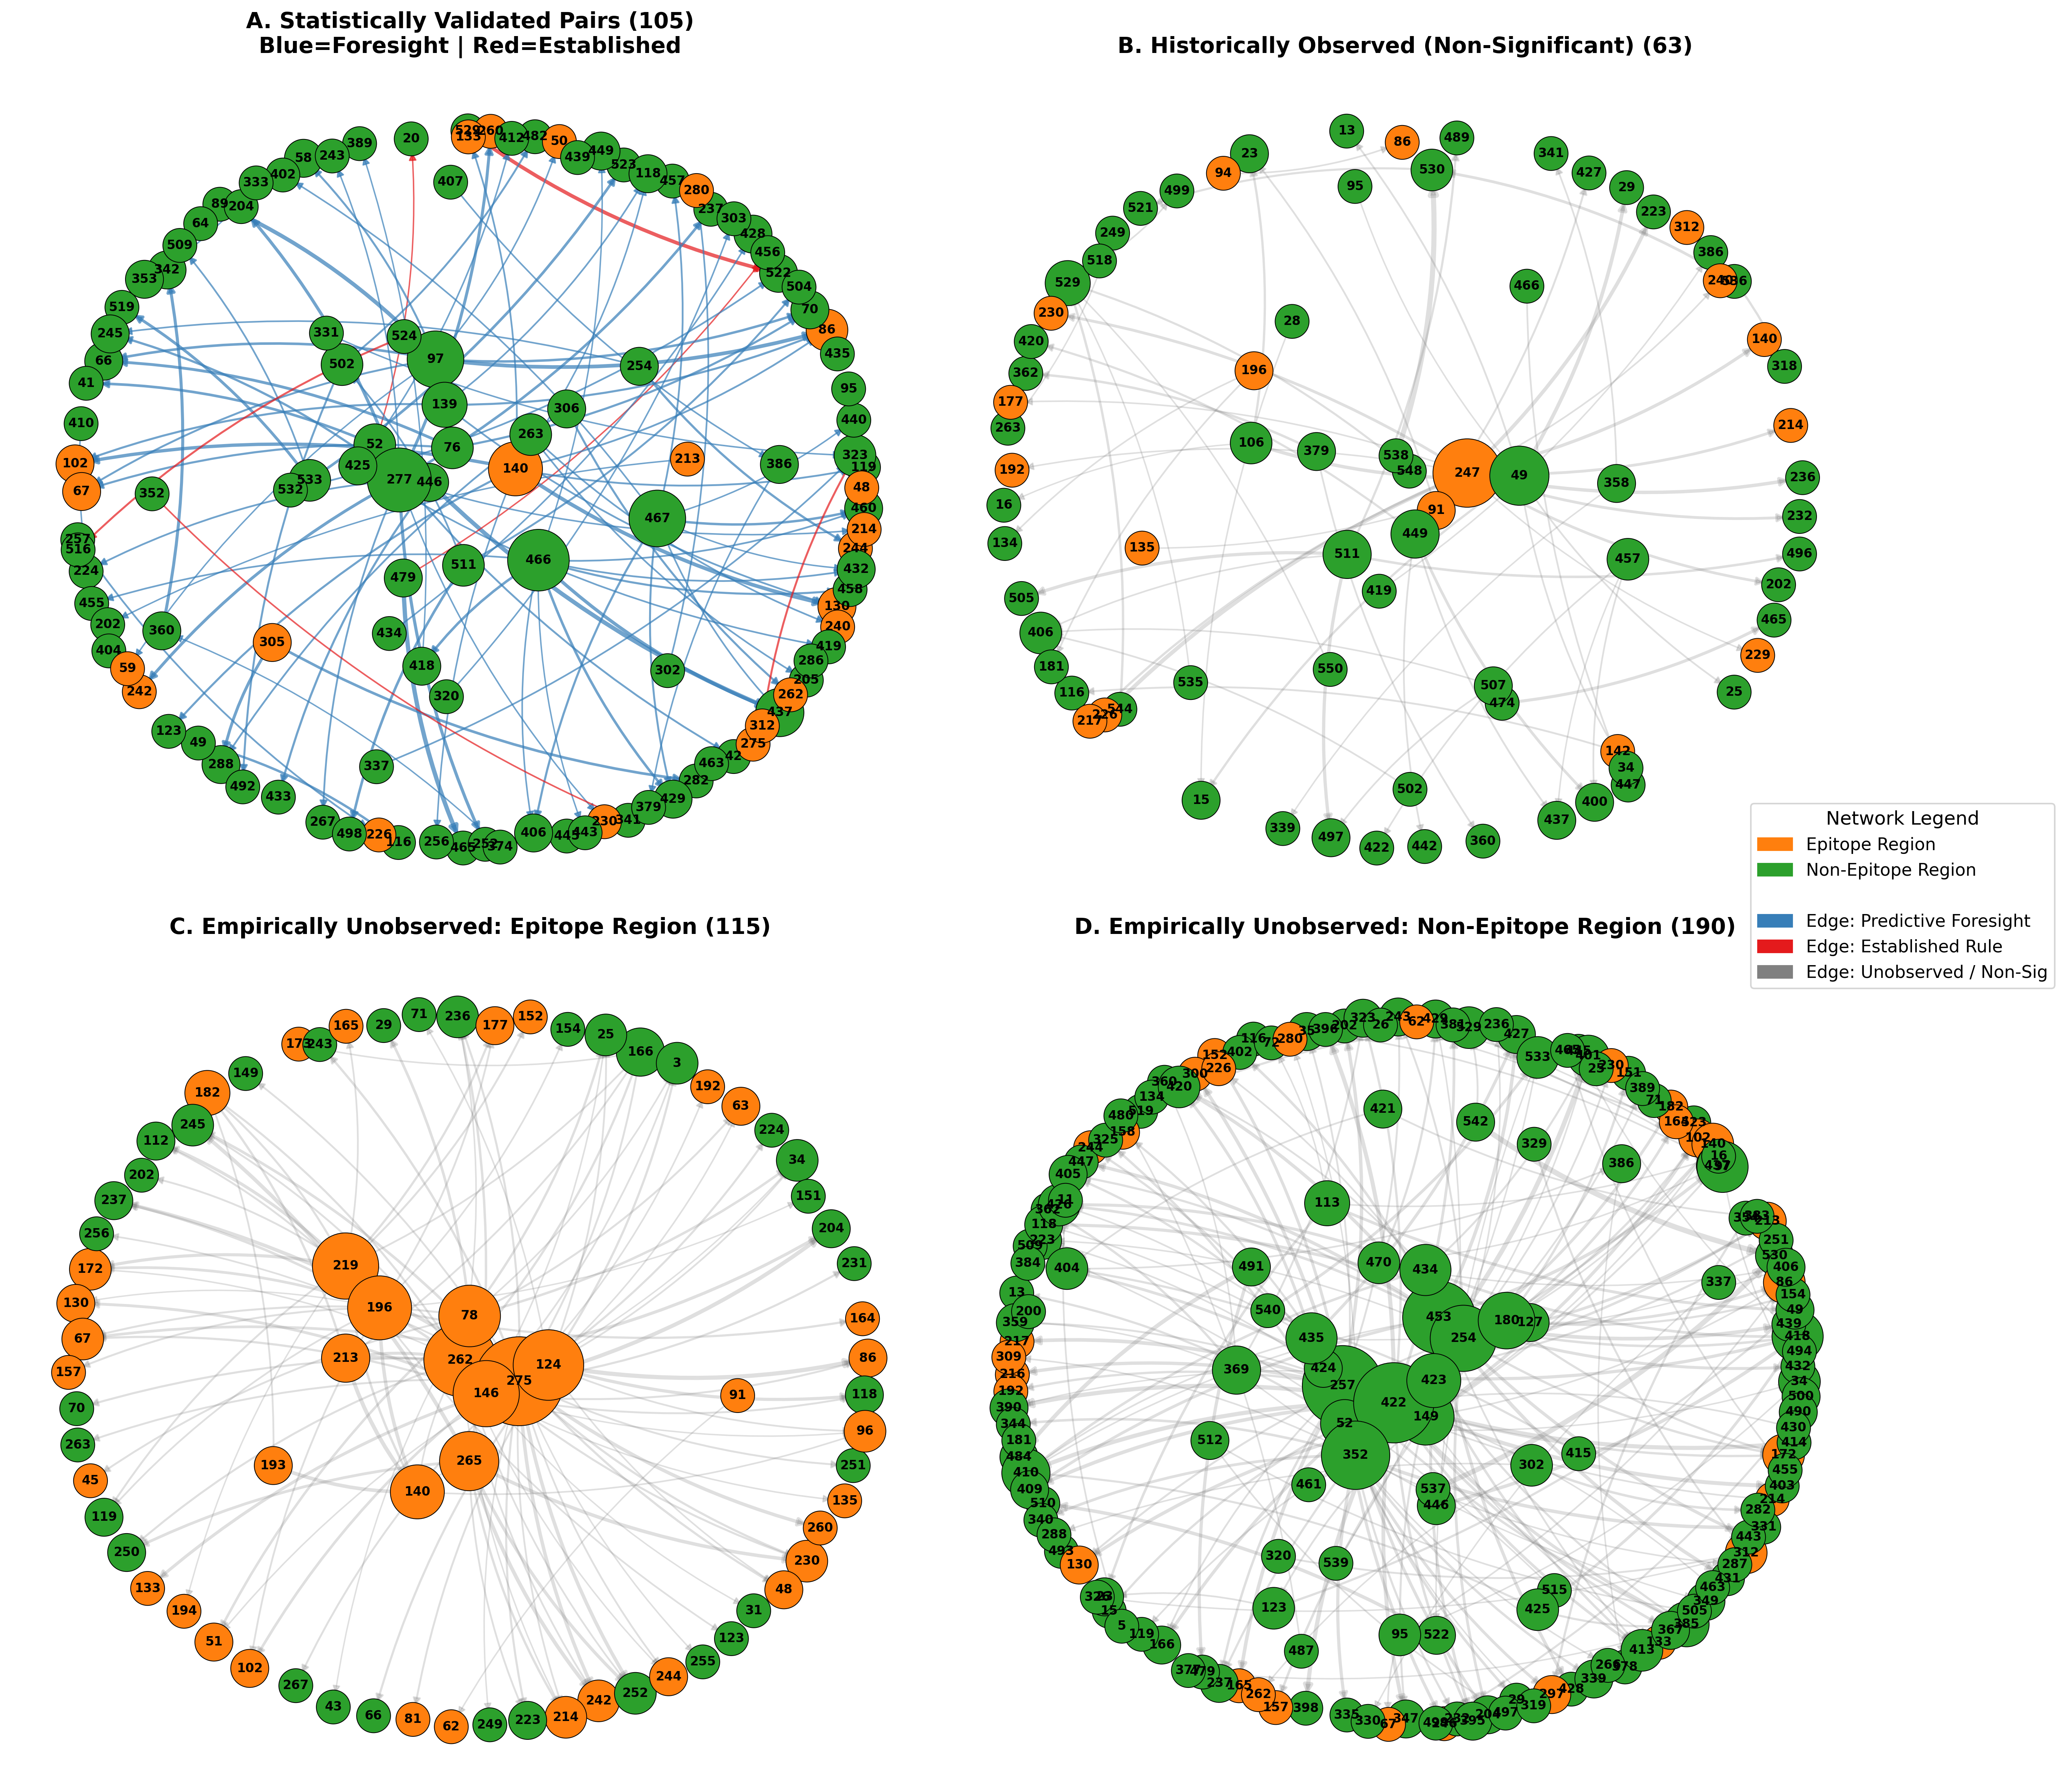

In [27]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd

# ==========================================
# SAVE THE FINAL ADJUSTED DATAFRAME TO CSV
# ==========================================
csv_filename = "Final_Adjusted_Epistasis_Pairs.csv"
comparison_df.to_csv(csv_filename, index=False)
print(f"Successfully saved all validated pair data to {csv_filename}")

# ==========================================
# 1. Define Subsets based on adjusted X_Tier
# ==========================================
is_validated = comparison_df['X_Tier'].isin([
    "Validated\n(Rare: <5 seqs)", 
    "Validated\n(Sufficient: >=5 seqs)"
])

is_observed_nonsig = comparison_df['X_Tier'] == "Observed\n(Non-Significant)"
is_unobserved = comparison_df['X_Tier'] == "Empirically\nUnobserved"
is_epitope = comparison_df['Mutated_Pos'].isin(all_epitope_positions)

df_validated = comparison_df[is_validated].copy()
df_observed_nonsig = comparison_df[is_observed_nonsig].copy()
df_unobserved_epi = comparison_df[is_unobserved & is_epitope].copy()
df_unobserved_non_epi = comparison_df[is_unobserved & ~is_epitope].copy()

# ==========================================
# 2. Setup a 2x2 Subplot Grid
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(18, 16), dpi=300)

panels = [
    (df_validated, axes[0, 0], f"A. Statistically Validated Pairs ({len(df_validated)})\nBlue=Foresight | Red=Established"),
    (df_observed_nonsig, axes[0, 1], f"B. Historically Observed (Non-Significant) ({len(df_observed_nonsig)})"),
    (df_unobserved_epi, axes[1, 0], f"C. Empirically Unobserved: Epitope Region ({len(df_unobserved_epi)})"),
    (df_unobserved_non_epi, axes[1, 1], f"D. Empirically Unobserved: Non-Epitope Region ({len(df_unobserved_non_epi)})")
]

for sub_df, ax, title in panels:
    G = nx.DiGraph()
    
    for _, row in sub_df.iterrows():
        u = row['Mutated_Pos']
        v = row['Affected_Pos']
        weight = row['Impact_Score']
        
        edge_color = 'gray'
        edge_alpha = 0.25 
        
        if title.startswith("A."):
            edge_alpha = 0.7 
            if row.get('Stack_Group') == "In Both (Global & Seasonal)":
                edge_color = '#e41a1c' # Red (Established)
            else:
                edge_color = '#377eb8' # Blue (Foresight)
                
        G.add_edge(u, v, weight=weight, color=edge_color, alpha=edge_alpha)
        
    if len(G.nodes) == 0:
        ax.text(0.5, 0.5, "No interactions found", ha='center', va='center', transform=ax.transAxes)
        ax.set_title(title, fontsize=14, weight='bold')
        ax.axis('off')
        continue

    node_colors = [get_node_color(node) for node in G.nodes()]
    node_sizes = [350 + (G.degree(node) * 120) for node in G.nodes()]

    pos = nx.spring_layout(G, k=3.5, iterations=300, seed=42) 

    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=node_colors, node_size=node_sizes, 
                           edgecolors='black', linewidths=0.5)
    
    for (u, v, d) in G.edges(data=True):
        nx.draw_networkx_edges(G, pos, ax=ax, edgelist=[(u, v)], width=d['weight']*1.8,
                               edge_color=d['color'], alpha=d['alpha'], 
                               arrowsize=10, connectionstyle="arc3,rad=0.1")
        
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=8, font_weight='bold', font_color='black')

    ax.set_title(title, fontsize=14, pad=15, weight='bold')
    ax.axis('off')

# ==========================================
# 3. Unified Legend
# ==========================================
legend_handles = [mpatches.Patch(color=color, label=label) for label, color in color_map.items()]
legend_handles.append(mpatches.Patch(color='white', label='')) 
legend_handles.append(mpatches.Patch(color='#377eb8', label='Edge: Predictive Foresight'))
legend_handles.append(mpatches.Patch(color='#e41a1c', label='Edge: Established Rule'))
legend_handles.append(mpatches.Patch(color='gray', label='Edge: Unobserved / Non-Sig'))

fig.legend(handles=legend_handles, title="Network Legend", loc='center right', 
           bbox_to_anchor=(1.02, 0.5), fontsize=11, title_fontsize=12)

plt.tight_layout(rect=[0, 0, 0.93, 1]) 
plt.savefig("epistasis_network_2x2_grid.png", dpi=300, bbox_inches='tight')
plt.show()